## Telco Customer Churn Pipeline|| CV + comparison || Tuning + test



In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/Telco-Customer-Churn.csv')

print(df.head())
print(df.describe())
print(df.info())
print(df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

## EDA + Data cleaning

In [8]:
# 0 keep copy in case
df_smth = df.copy()

# 1 drop ID
df = df.drop(columns=['customerID'])

# check missing and duplicates
# print(df.isnull().sum())
# print(df.duplicated().sum())
# no missing no duplicates

# 2 fix TotalCharges str -> numeric and handle nan
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(r"^\s*$", pd.NA, regex=True), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 3 Encoding column for 1 and 0:
bin_cols = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
    "Churn"
]

for col in bin_cols:
    if col == 'gender':
        df[col] = df[col].map({'Female': 0, 'Male': 1})
    else:
        df[col] = df[col].map({'No': 0, 'Yes': 1})


# 4 one hot encoding (multicategory columns)
multi_cols = [
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaymentMethod"
]

df = pd.get_dummies(
    df,
    columns=multi_cols,
    drop_first=True,
    dtype=int,
)

print(df.head())
print(df.shape)

   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   
2       1              0        0           0       2             1   
3       1              0        0           0      45             0   
4       0              0        0           0       2             1   

   PaperlessBilling  MonthlyCharges  TotalCharges  Churn  ... TechSupport_Yes  \
0                 1           29.85         29.85      0  ...               0   
1                 0           56.95       1889.50      0  ...               0   
2                 1           53.85        108.15      1  ...               0   
3                 0           42.30       1840.75      0  ...               1   
4                 1           70.70        151.65      1  ...               0   

   StreamingTV_No internet service  StreamingTV_Yes  \
0                              

In [9]:
# use cut method
df['tenure_grouped'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, float('inf')],
    labels=['0-12', '13-24', '25-52', '49+']
)

pd.crosstab(df['tenure_grouped'], df['Churn'], normalize='index')

# tenure_grouped	No                      Yes
# 0-12	            0.525618	            0.474382
# 13-24	            0.712891	            0.287109
# 25-52	            0.796110	            0.203890
# 49+	            0.904868	            0.09513

# conclusion from here, if person stayed little , theres high possibility that he leaves

Churn,0,1
tenure_grouped,,
0-12,0.525618,0.474382
13-24,0.712891,0.287109
25-48,0.796110,0.203890
49+,0.904868,0.095132


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   gender                                 7043 non-null   int64   
 1   SeniorCitizen                          7043 non-null   int64   
 2   Partner                                7043 non-null   int64   
 3   Dependents                             7043 non-null   int64   
 4   tenure                                 7043 non-null   int64   
 5   PhoneService                           7043 non-null   int64   
 6   PaperlessBilling                       7043 non-null   int64   
 7   MonthlyCharges                         7043 non-null   float64 
 8   TotalCharges                           7043 non-null   float64 
 9   Churn                                  7043 non-null   int64   
 10  tenure_grouped                         7043 non-null   category
 11  Mu

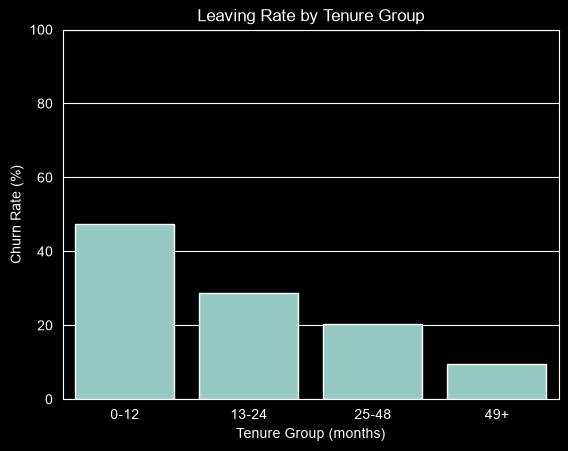

In [10]:
churn_rate = pd.crosstab(
    df['tenure_grouped'],
    df['Churn'],
    normalize='index'
)[1] * 100

sns.barplot(x=churn_rate.index, y=churn_rate.values)

plt.xlabel('Tenure Group (months)')
plt.ylabel('Churn Rate (%)')
plt.title('Leaving Rate by Tenure Group')
plt.ylim(0, 100)

# kam ishlatgan userla tez ketib qoladi

print(df.info())

Churn
0    5174
1    1869
Name: count, dtype: int64


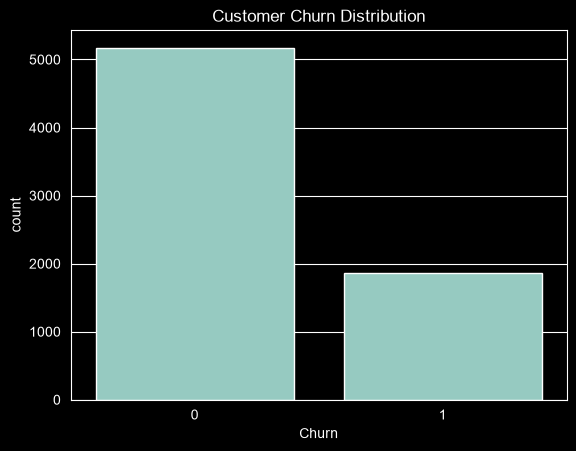

In [13]:
# Target distribuition
print(df['Churn'].value_counts())

sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.show()

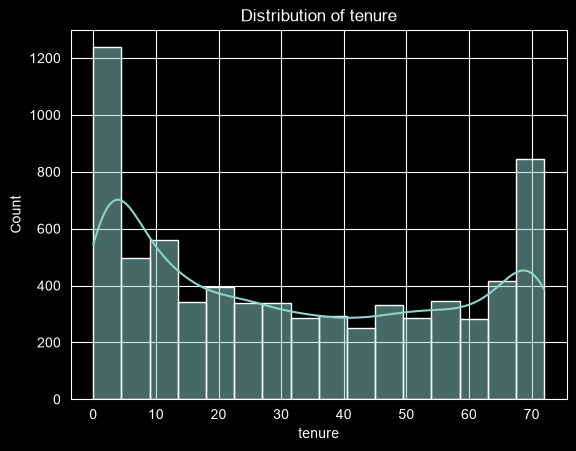

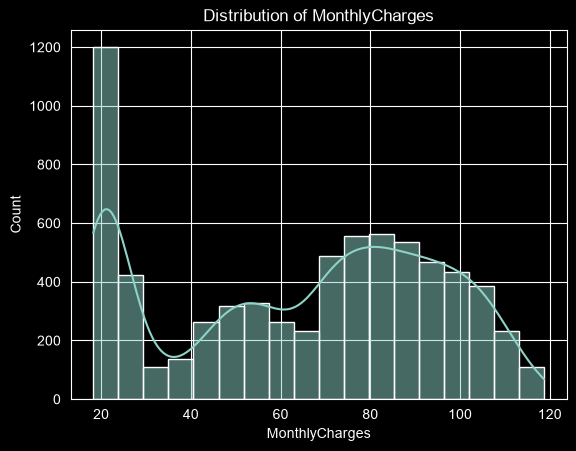

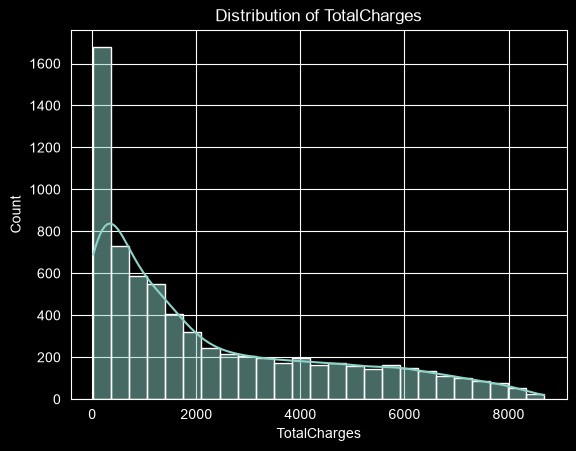

In [14]:
# Numerical features distribution
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in num_cols:
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

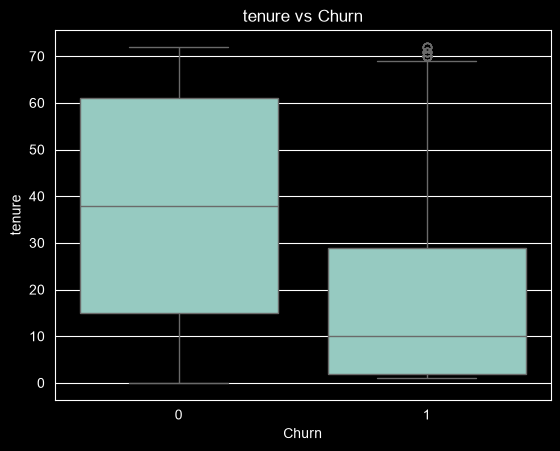

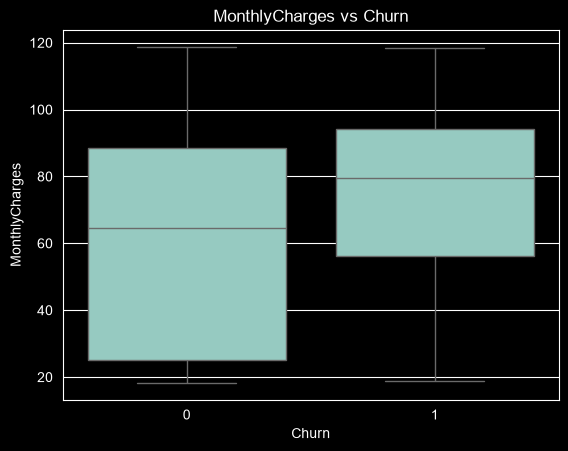

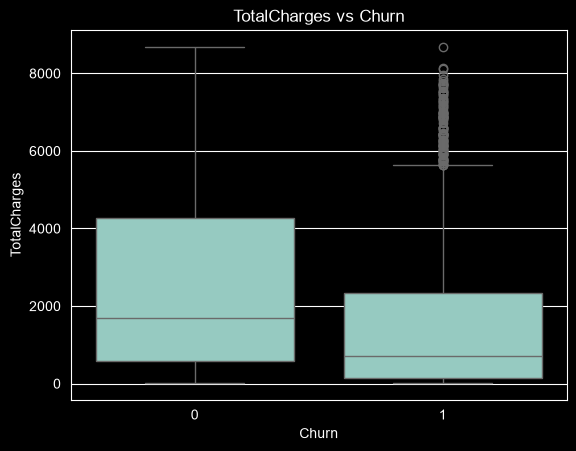

In [15]:
# Numerical features vs target
for col in num_cols:
    sns.boxplot(data=df, x='Churn', y=col)
    plt.title(f'{col} vs Churn')
    plt.show()

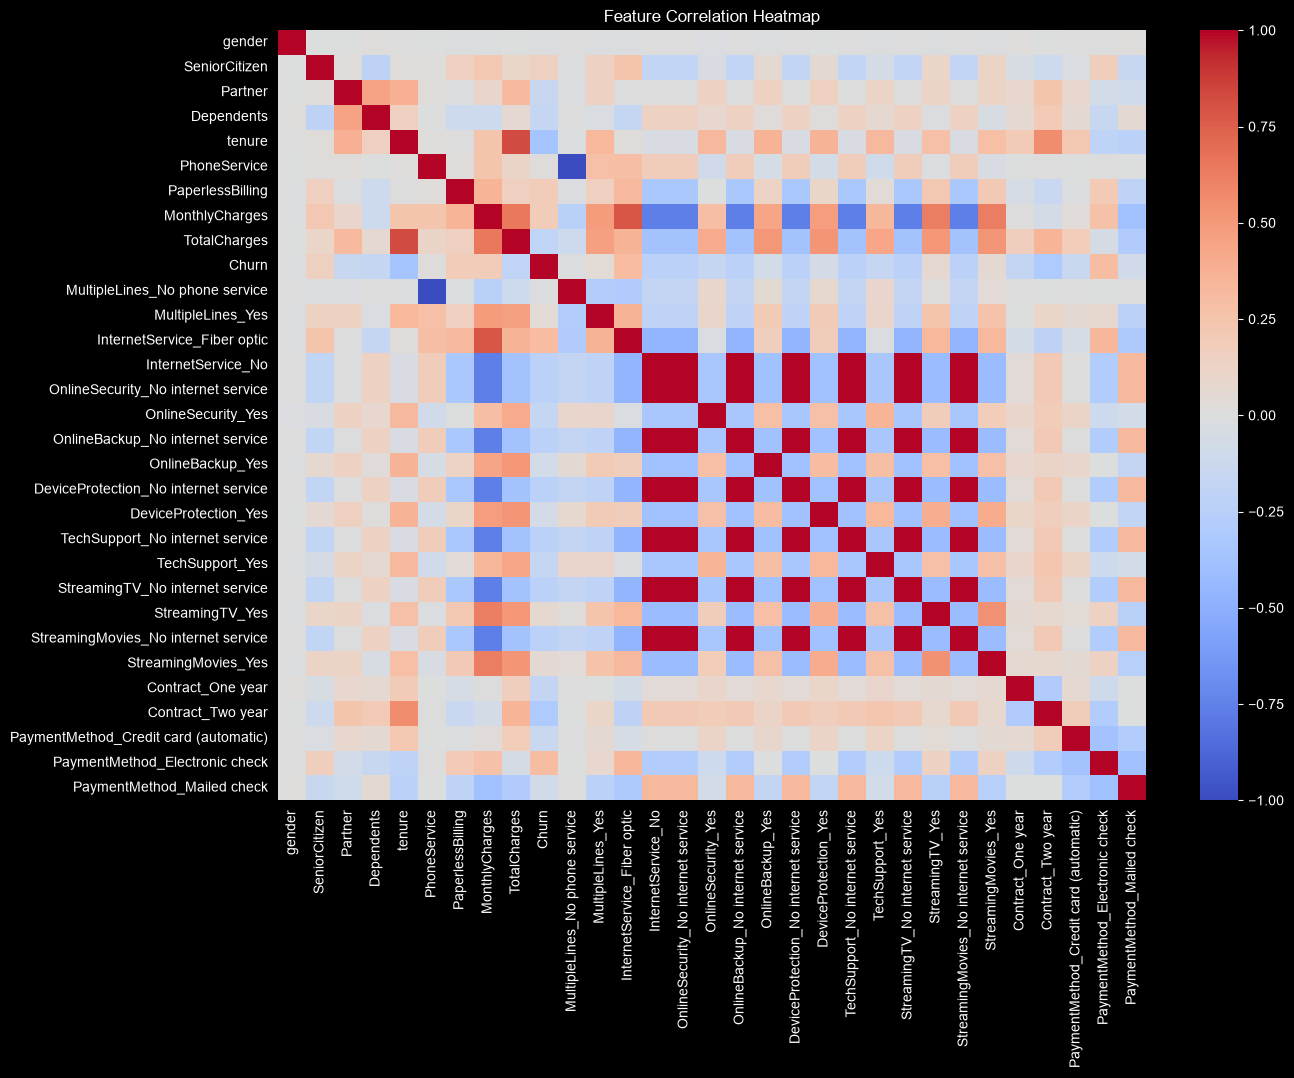

In [16]:
# Correlation matrix
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap='coolwarm',
    center=0
)

plt.title('Feature Correlation Heatmap')
plt.show()

# Pipeline

In [17]:
# split train/test
from sklearn.model_selection import train_test_split

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# split num and cat columns
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include='object').columns

In [19]:
# pipeline for numerical features
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# pipeline for categorical features
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [20]:
# combine them
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# StratifiedKfold + model comparison

In [21]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# define 3 models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [22]:
from sklearn.model_selection import cross_validate
scoring = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

results = {}

for name, model in models.items():

    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    scores = cross_validate(
        pipe,
        X,
        y,
        cv=5,
        scoring=scoring,
        n_jobs=-1
    )

    results[name] = scores

In [25]:
rows = [] # rowlani qoshib table qvoramiz

for name, scores in results.items():
    row = {'Model': name}
    for metric in scoring:
        values = scores[f'test_{metric}']

        row[metric] = (
            f"{values.mean():.4f} ± {values.std():.4f}"
        )

    rows.append(row)

results_df = pd.DataFrame(rows)

print(results_df.to_string(index=False))


best_name = max(
    results,
    key=lambda name: results[name]['test_recall'].mean()
)

print("Selected model:", best_name)

              Model        accuracy       precision          recall              f1         roc_auc
Logistic Regression 0.8042 ± 0.0073 0.6553 ± 0.0143 0.5527 ± 0.0222 0.5996 ± 0.0179 0.8453 ± 0.0110
      Random Forest 0.7893 ± 0.0103 0.6395 ± 0.0290 0.4746 ± 0.0181 0.5445 ± 0.0191 0.8229 ± 0.0130
  Gradient Boosting 0.8065 ± 0.0077 0.6716 ± 0.0209 0.5308 ± 0.0097 0.5929 ± 0.0129 0.8453 ± 0.0099
Selected model: Logistic Regression


# Tuning + test


In [24]:
param_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10],
        'model__class_weight': [None, 'balanced']
    },

    'Random Forest': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [None, 10, 20],
        'model__min_samples_split': [2, 5],
        'model__class_weight': [None, 'balanced']
    },

    'Gradient Boosting': {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.05, 0.1],
        'model__max_depth': [2, 3]
    }
}

In [26]:
from sklearn.model_selection import GridSearchCV

best_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', models[best_name])
])

grid_search = GridSearchCV(
    estimator=best_pipe,
    param_grid=param_grids[best_name],
    scoring='recall',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`

In [28]:
from sklearn.model_selection import GridSearchCV

best_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', models[best_name])
])

grid_search = GridSearchCV(
    estimator=best_pipe,
    param_grid=param_grids[best_name],
    scoring='recall',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`

In [29]:
print("Best parameters:", grid_search.best_params_)
print("Best CV Recall:", grid_search.best_score_)

final_model = grid_search.best_estimator_

Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Best CV Recall: 0.8033444816053512


# Final test evaluation

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

In [32]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7388218594748048
Precision: 0.5051903114186851
Recall: 0.7807486631016043
F1: 0.6134453781512605
ROC-AUC: 0.8412333049161694


In [35]:
print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred))

[[749 286]
 [ 82 292]]
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



# Permutation importance + 3 customer

In [36]:
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring='recall',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [37]:
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': permutation.importances_mean,
    'Std': permutation.importances_std
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                                  Feature  Importance       Std
4                                  tenure    0.235294  0.006439
12            InternetService_Fiber optic    0.131016  0.017816
27                      Contract_Two year    0.087968  0.011865
7                          MonthlyCharges    0.037433  0.011469
26                      Contract_One year    0.005080  0.006812
29         PaymentMethod_Electronic check    0.001872  0.005615
28  PaymentMethod_Credit card (automatic)    0.000000  0.000000
9                          tenure_grouped    0.000000  0.000000
0                                  gender   -0.000535  0.001070
17                       OnlineBackup_Yes   -0.001070  0.001310
30             PaymentMethod_Mailed check   -0.001070  0.001310
1                           SeniorCitizen   -0.001604  0.003209
5                            PhoneService   -0.001872  0.001225
10         MultipleLines_No phone service   -0.001872  0.001225
6                        PaperlessBillin

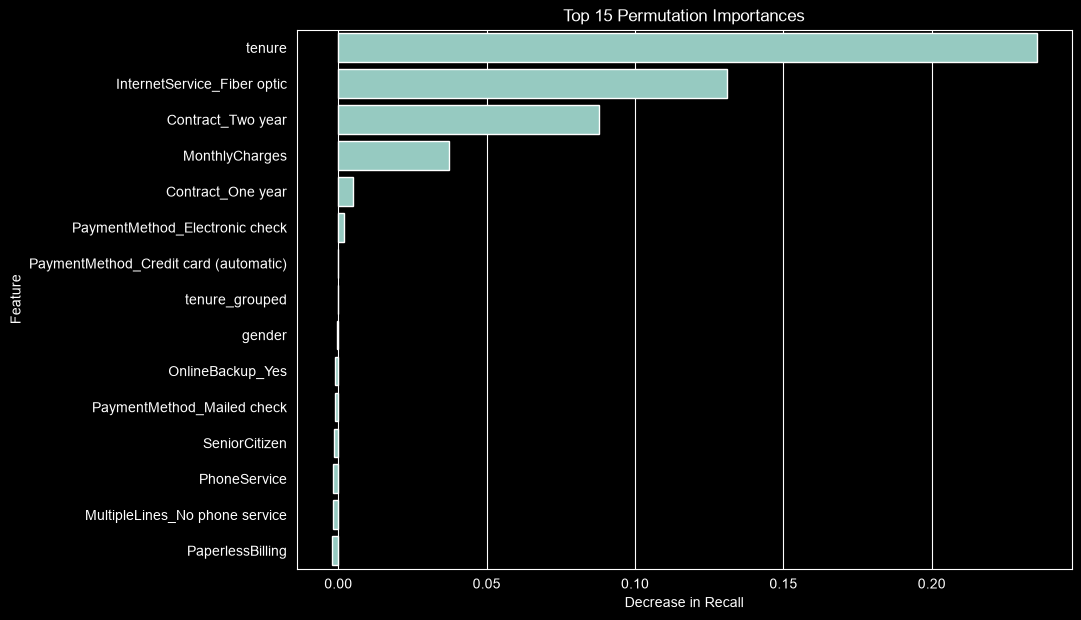

In [38]:
# visualize
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Permutation Importances')
plt.xlabel('Decrease in Recall')
plt.ylabel('Feature')

plt.show()

# Shap waterfall - 3 customer

In [48]:
import shap
customers = X_test.iloc[:3]

# transform
preprocessor_fitted = final_model.named_steps['preprocessor']

X_train_transformed = preprocessor_fitted.transform(X_train)
X_test_transformed = preprocessor_fitted.transform(customers)

feature_names = preprocessor_fitted.get_feature_names_out()

X_train_transformed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names
)

X_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names
)

In [49]:
# explainer
model = final_model.named_steps['model']

background = X_train_transformed.sample(
    100,
    random_state=42
)

explainer = shap.Explainer(
    model.predict_proba,
    shap.maskers.Independent(background),
    algorithm='permutation'
)

In [50]:
# calculate
shap_values = explainer(
    X_test_transformed,
    max_evals=2 * X_train_transformed.shape[1] + 1
)

/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LogisticR

Customer 1


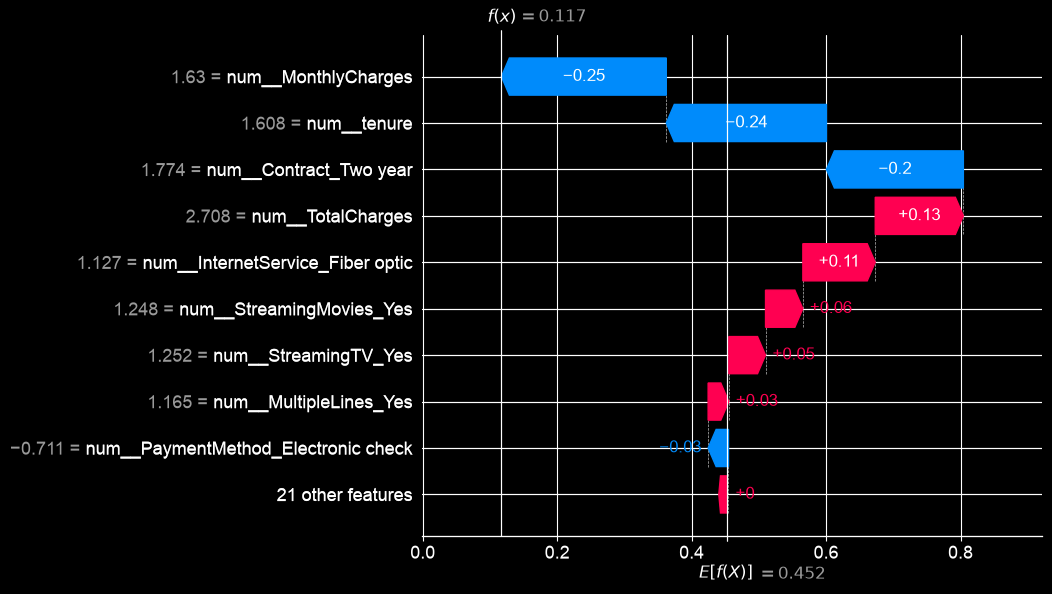

Customer 2


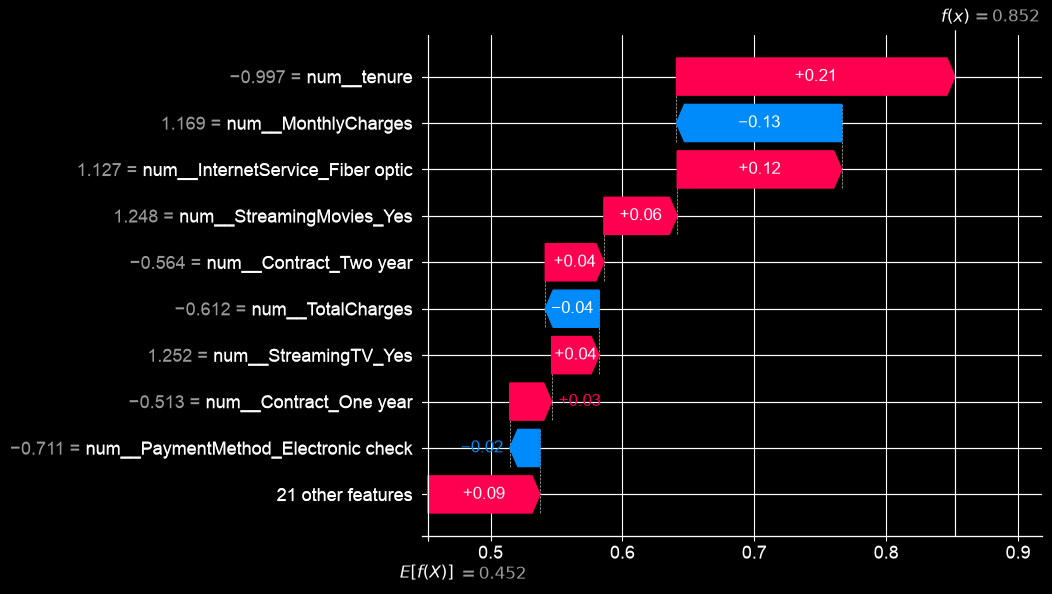

Customer 3


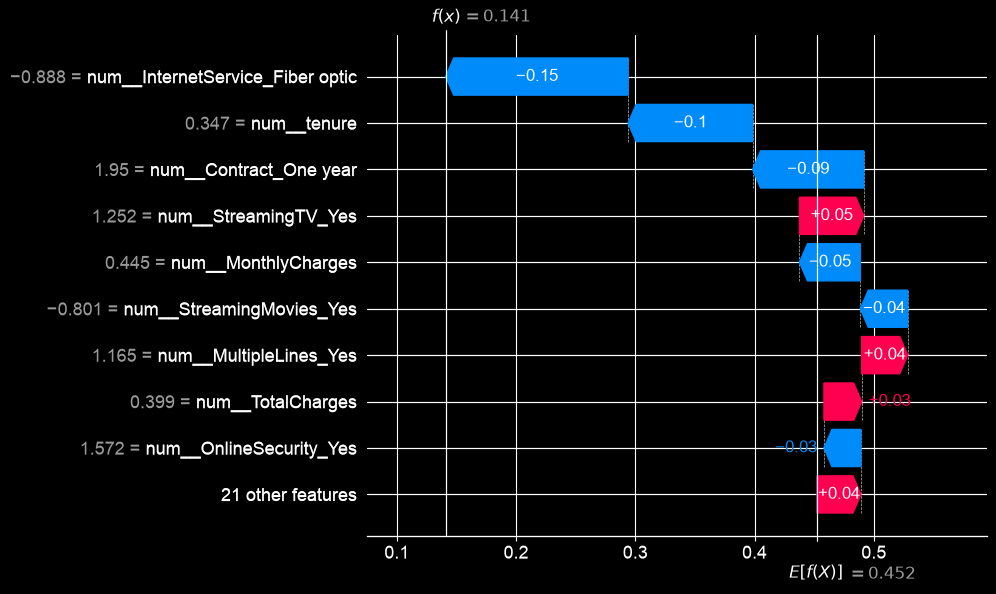

In [51]:
# visualise shap plot for each customer
for i in range(3):
    print(f"Customer {i + 1}")
    shap.plots.waterfall(
        shap_values[i, :, 1]
    )